<a href="https://colab.research.google.com/github/ljn11112/odometry3/blob/main/notebooks/odometry-exercise-03-wheel-separation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Odometry Exercise 3 — plotting rotation data

Load a timestamped rotation log, plot the signed encoder counts and local odometry heading, and compare final reported rotation with your independent physical-angle measurements.

This notebook is an introduction to plotting odometry data. Start with the supplied synthetic example so that you can see what each cell produces. The example is not evidence about your robot. When you are ready, change the settings in the **Use your own data** cell and run the notebook again.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(2026)


## 1. Use the example or your own data

Leave `USE_EXAMPLE_DATA` set to `True` on your first run. To use your measurements, upload the CSV exported from the Serial Monitor, set `USE_EXAMPLE_DATA = False`, and enter its filename. This is the main cell you need to edit.


In [2]:
USE_EXAMPLE_DATA = False
CSV_FILENAME = "rotation_data.csv"

print("Using:", "synthetic example" if USE_EXAMPLE_DATA else CSV_FILENAME)


Using: rotation_data.csv


## 2. Create the small synthetic example

Run this cell when using the example. You do not need to understand or edit the generation code. Its columns match the rotation log in Exercise 3.


In [3]:
example_rows = []
example_conditions = [
    (1, np.pi / 2, 1.48, 2.0),
    (2, -np.pi / 2, -1.50, 1.5),
    (3, np.pi, 2.98, 3.0),
    (4, -np.pi, -3.01, 2.5),
]

for trial_num, command_rad, final_heading_rad, centre_motion_mm in example_conditions:
    for sample_num, progress in enumerate(np.linspace(0, 1, 31)):
        turn_sign = np.sign(final_heading_rad)
        wheel_count = progress * abs(final_heading_rad) * 170
        example_rows.append({
            "test_name": "rotation",
            "trial_num": trial_num,
            "commanded_angle_rad": command_rad,
            "sample_time_ms": 1000 * trial_num + 50 * sample_num,
            "left_encoder_count": round(-turn_sign * wheel_count),
            "right_encoder_count": round(turn_sign * wheel_count),
            "odometry_x_mm": centre_motion_mm * np.sin(np.pi * progress),
            "odometry_y_mm": centre_motion_mm * np.sin(2 * np.pi * progress) / 2,
            "odometry_theta_rad": progress * final_heading_rad,
        })

example_data = pd.DataFrame(example_rows)


## 3. Load and preview the selected data

When `USE_EXAMPLE_DATA` is false, `pd.read_csv(...)` reads your file. The final line displays its first five rows.


In [8]:
if USE_EXAMPLE_DATA:
    data = example_data.copy()
else:
    data = pd.read_csv(CSV_FILENAME)

data.head()


,test_name,trial_num,commanded_angle_rad,sample_time_ms,left_encoder_count,right_encoder_count,odometry_x_mm,odometry_y_mm,odometry_theta_rad
0,rotation1,1,1.5708,8058,0,0,0.0,0.0,0.0
1,rotation1,1,1.5708,8068,0,0,0.0,0.0,0.0
2,rotation1,1,1.5708,8078,0,0,0.0,0.0,0.0
3,rotation1,1,1.5708,8088,0,0,0.0,0.0,0.0
4,rotation1,1,1.5708,8098,0,0,0.0,0.0,0.0


## 4. Calculate elapsed time

Subtract the first timestamp in each trial so that every plot begins at zero seconds. The heading is also converted to degrees for plotting.


In [9]:

# Keep all four rotation conditions
data = data.loc[
    data["test_name"].isin([
        "rotation1",
        "rotation2",
        "rotation3",
        "rotation4"
    ])
].copy()

# Sort by trial number and timestamp
data = data.sort_values(["trial_num", "sample_time_ms"])

# Calculate elapsed time for each trial
data["elapsed_s"] = (
    data["sample_time_ms"]
    - data.groupby("trial_num")["sample_time_ms"].transform("first")
) / 1000

# Convert heading from radians to degrees
data["heading_deg"] = np.degrees(data["odometry_theta_rad"])

# Create trial labels
data["trial_label"] = (
    data["test_name"] + " - Trial " + data["trial_num"].astype(str)
)

# Preview the data
data[[
    "test_name",
    "trial_num",
    "sample_time_ms",
    "elapsed_s",
    "heading_deg"
]].head()


,test_name,trial_num,sample_time_ms,elapsed_s,heading_deg
0,rotation1,1,8058,0.00,0.0
1,rotation1,1,8068,0.01,0.0
2,rotation1,1,8078,0.02,0.0
3,rotation1,1,8088,0.03,0.0
4,rotation1,1,8098,0.04,0.0


## 5. Plot both encoder counts

An in-place rotation should produce encoder-count changes with opposite signs. The plot lets you see how the two recorded count sequences developed during each turn.


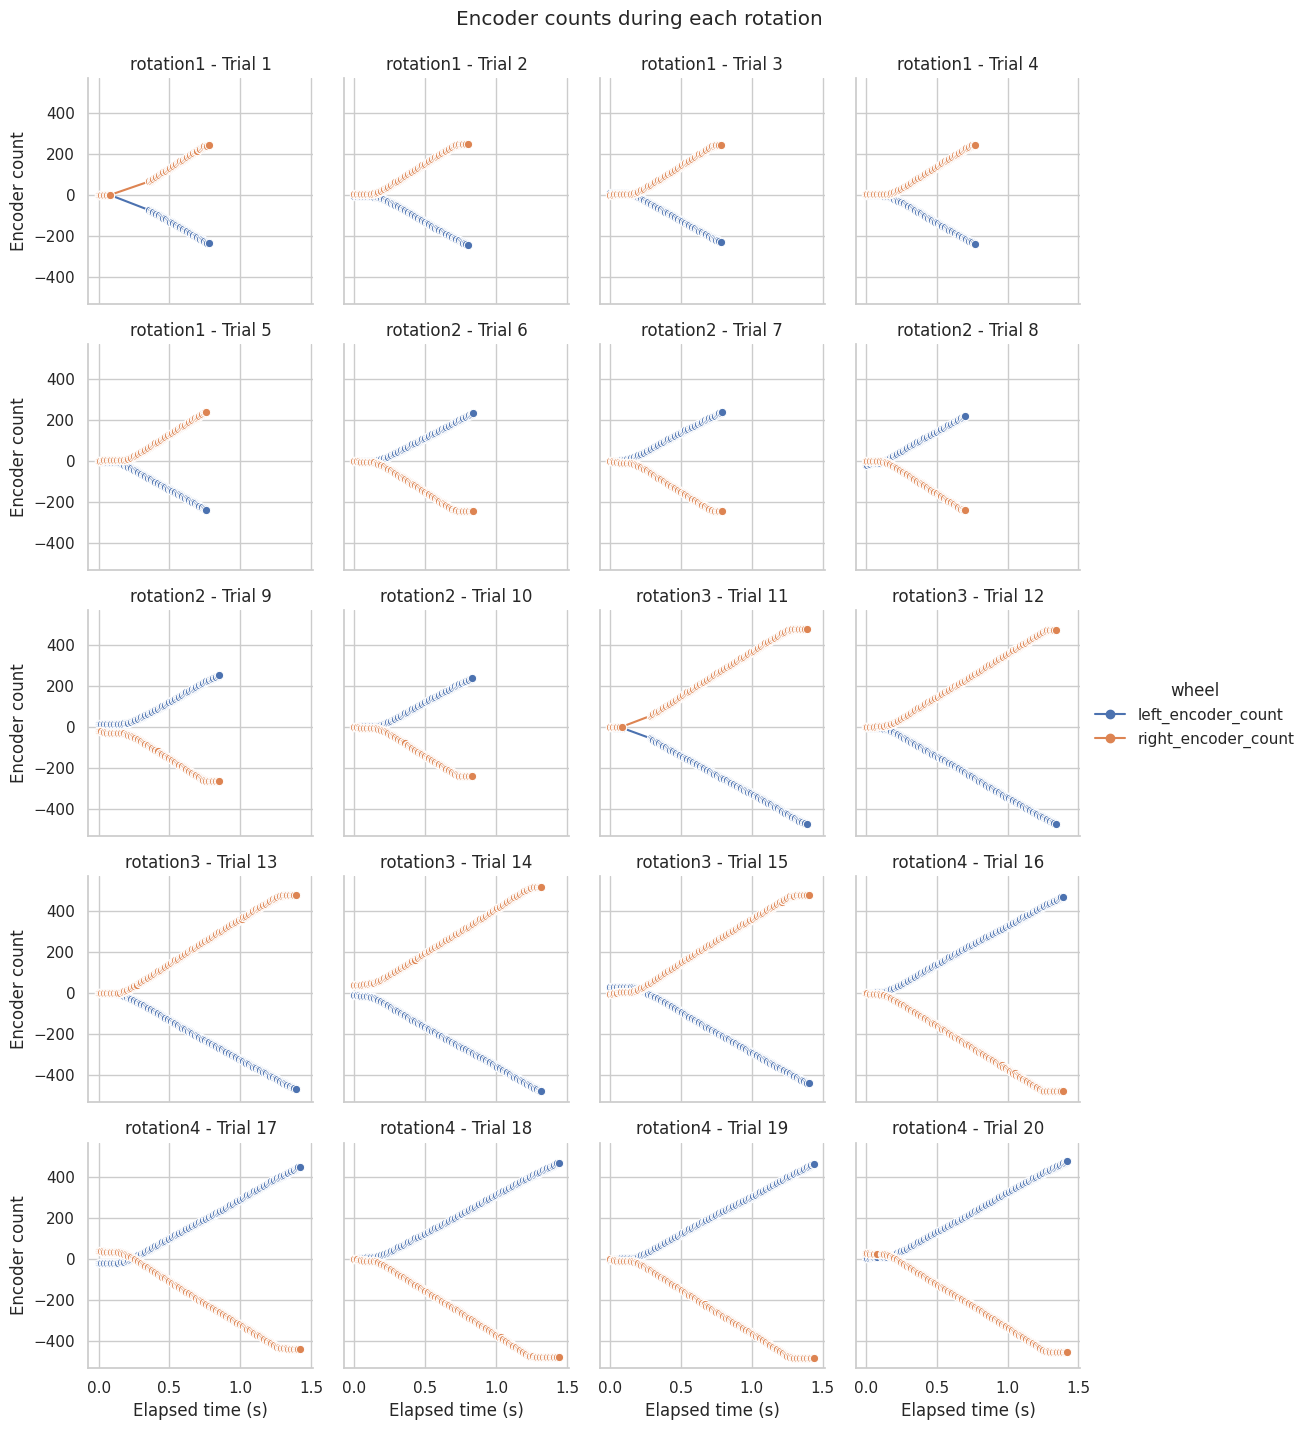

In [11]:

encoder_plot_data = data.melt(
    id_vars=["trial_num", "trial_label", "elapsed_s"],
    value_vars=["left_encoder_count", "right_encoder_count"],
    var_name="wheel",
    value_name="encoder_count",
)

grid = sns.relplot(
    data=encoder_plot_data,
    x="elapsed_s",
    y="encoder_count",
    hue="wheel",
    col="trial_label",
    col_wrap=4,
    kind="line",
    marker="o",
    estimator=None,
    height=2.8,
)

grid.set_axis_labels("Elapsed time (s)", "Encoder count")
grid.set_titles("{col_name}")
grid.figure.suptitle(
    "Encoder counts during each rotation",
    y=1.02
)

plt.show()


## 6. Plot the reported heading

This plot shows the heading accumulated by the local odometry model. It does not show the independently measured physical rotation.


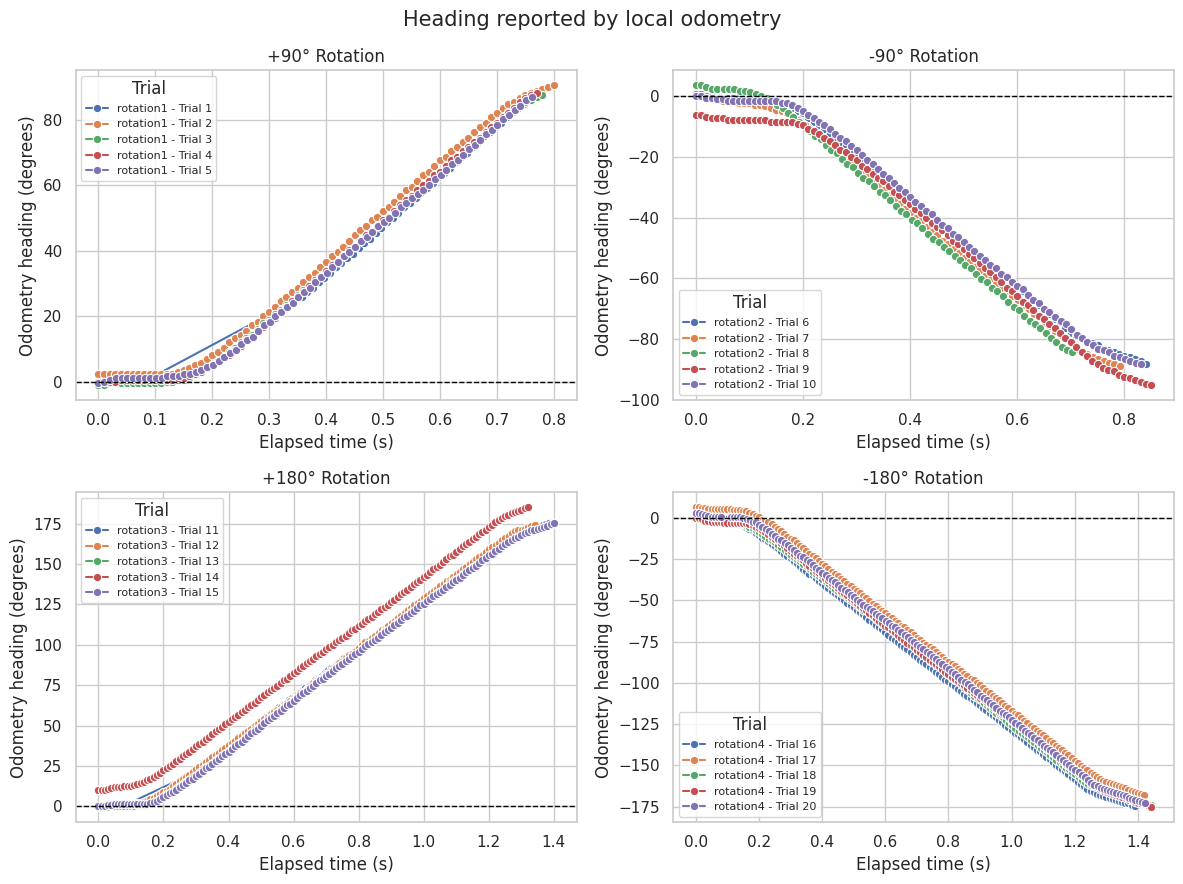

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

conditions = ["rotation1", "rotation2", "rotation3", "rotation4"]
titles = ["+90° Rotation", "-90° Rotation",
          "+180° Rotation", "-180° Rotation"]

for ax, condition, title in zip(axes.flat, conditions, titles):
    subset = data[data["test_name"] == condition]

    sns.lineplot(
        data=subset,
        x="elapsed_s",
        y="heading_deg",
        hue="trial_label",
        marker="o",
        estimator=None,
        ax=ax,
    )

    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set(
        title=title,
        xlabel="Elapsed time (s)",
        ylabel="Odometry heading (degrees)",
    )
    ax.legend(title="Trial", fontsize=8)

plt.suptitle("Heading reported by local odometry", fontsize=15)
plt.tight_layout()
plt.show()


## 7. Plot reported movement of the robot centre

For an ideal rotation on the spot, x and y would remain unchanged. This is still only the local model's report, so compare it with what you observed physically.


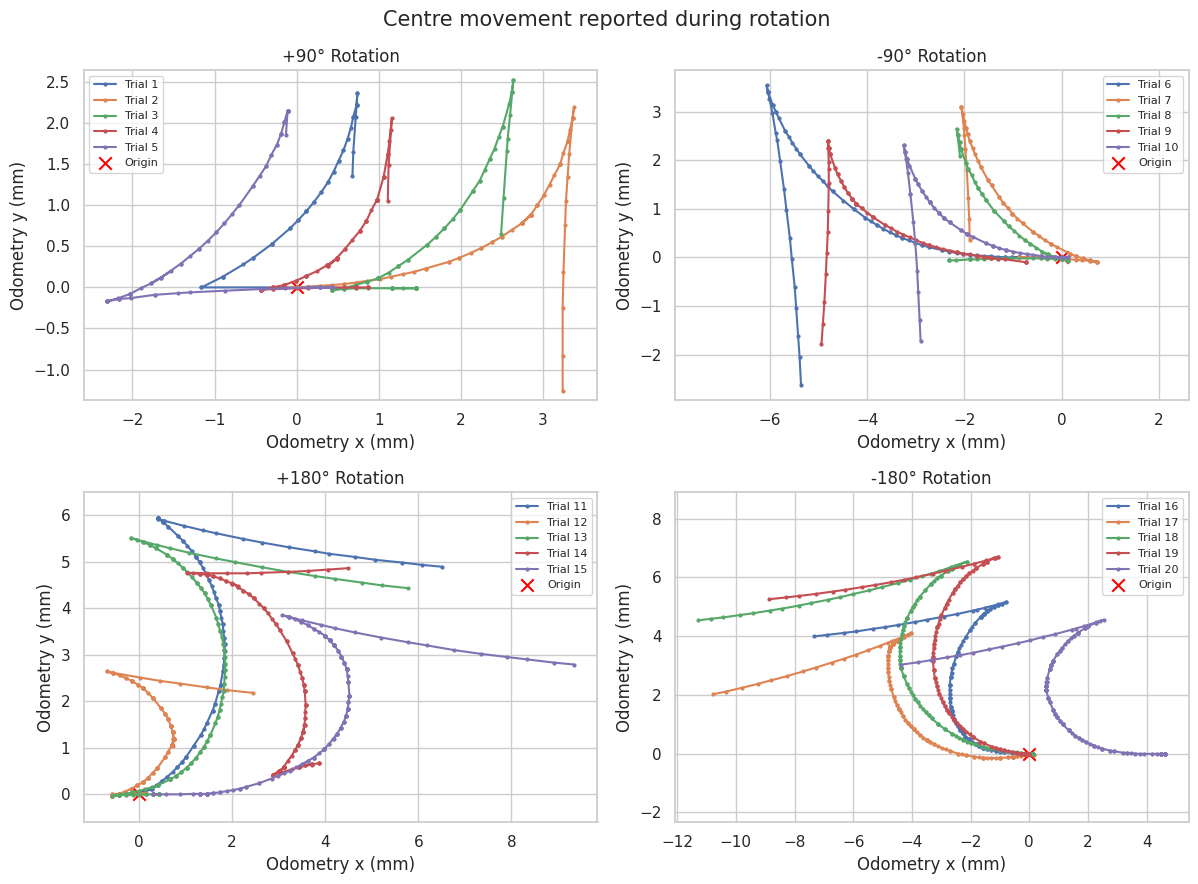

In [16]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

conditions = ["rotation1", "rotation2", "rotation3", "rotation4"]
titles = ["+90° Rotation", "-90° Rotation",
          "+180° Rotation", "-180° Rotation"]

for ax, condition, title in zip(axes.flat, conditions, titles):

    subset = data[data["test_name"] == condition]

    for trial_num, trial_data in subset.groupby("trial_num"):

        # Make sure points are ordered by time
        trial_data = trial_data.sort_values("sample_time_ms")

        ax.plot(
            trial_data["odometry_x_mm"],
            trial_data["odometry_y_mm"],
            marker="o",
            markersize=2,
            linewidth=1.5,
            label=f"Trial {trial_num}"
        )

    ax.scatter(
        0, 0,
        color="red",
        marker="x",
        s=80,
        label="Origin"
    )

    ax.set(
        title=title,
        xlabel="Odometry x (mm)",
        ylabel="Odometry y (mm)"
    )

    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(fontsize=8)

plt.suptitle(
    "Centre movement reported during rotation",
    fontsize=15
)

plt.tight_layout()
plt.show()


## 8. Extract the initial and final reported headings

The following cell creates one row per trial and calculates the change between its first and final odometry headings and centre positions.


In [18]:

# Extract initial and final odometry values for each trial
trial_summary = (
    data.sort_values(["trial_num", "sample_time_ms"])
    .groupby(["test_name", "trial_num"], as_index=False)
    .agg(
        commanded_angle_rad=("commanded_angle_rad", "first"),
        initial_x_mm=("odometry_x_mm", "first"),
        initial_y_mm=("odometry_y_mm", "first"),
        initial_heading_rad=("odometry_theta_rad", "first"),
        final_heading_rad=("odometry_theta_rad", "last"),
        final_x_mm=("odometry_x_mm", "last"),
        final_y_mm=("odometry_y_mm", "last"),
    )
)

# Calculate reported rotation
trial_summary["reported_angle_rad"] = (
    trial_summary["final_heading_rad"]
    - trial_summary["initial_heading_rad"]
)

trial_summary["reported_angle_deg"] = np.degrees(
    trial_summary["reported_angle_rad"]
)

# Convert commanded angle to degrees
trial_summary["commanded_angle_deg"] = np.degrees(
    trial_summary["commanded_angle_rad"]
)

# Calculate reported centre movement
trial_summary["reported_centre_change_x_mm"] = (
    trial_summary["final_x_mm"]
    - trial_summary["initial_x_mm"]
)

trial_summary["reported_centre_change_y_mm"] = (
    trial_summary["final_y_mm"]
    - trial_summary["initial_y_mm"]
)

# Calculate final centre displacement
trial_summary["centre_displacement_mm"] = np.sqrt(
    trial_summary["reported_centre_change_x_mm"]**2
    + trial_summary["reported_centre_change_y_mm"]**2
)

# Display the summary
trial_summary[[
    "test_name",
    "trial_num",
    "commanded_angle_deg",
    "reported_angle_deg",
    "reported_centre_change_x_mm",
    "reported_centre_change_y_mm",
    "centre_displacement_mm"
]]


,test_name,trial_num,commanded_angle_deg,reported_angle_deg,reported_centre_change_x_mm,reported_centre_change_y_mm,centre_displacement_mm
0,rotation1,1,90.000210,87.662543,0.68,1.36,1.520526
1,rotation1,2,90.000210,88.235500,3.38,-1.26,3.607215
2,rotation1,3,90.000210,88.808458,1.33,0.66,1.484756
3,rotation1,4,90.000210,88.235500,0.24,1.05,1.077079
4,rotation1,5,90.000210,87.662543,-0.42,1.86,1.906830
5,rotation2,6,-90.000210,-88.808458,-5.07,-2.63,5.711550
6,rotation2,7,-90.000210,-88.808458,-1.89,0.35,1.922134
7,rotation2,8,-90.000210,-87.662543,0.22,2.14,2.151279
8,rotation2,9,-90.000210,-88.808458,-4.21,-1.69,4.536541
9,rotation2,10,-90.000210,-88.235500,-2.90,-1.72,3.371706


## 9. Enter your physical angle measurements

The robot log does not contain the angle you measured on the printed sheet. Enter the independently measured start and final headings below in degrees. Use the same positive and negative convention as the odometry. Add or remove rows so that the trial numbers match your log. Record the radius and separation used by the model during each trial, and label the row as `calibration` or `held-back`.


In [19]:

# Step 9: Enter physical angle measurements

physical_measurements = pd.DataFrame({
    "trial_num": list(range(1, 21)),

    # All trials started at 0 degrees
    "measured_start_heading_deg": [0.0] * 20,

    # Independently measured final angles
    "measured_final_heading_deg": [
        92, 92, 92, 93, 92,
        -94, -95, -94, -95, -95,
        182, 180, 183, 182, 184,
        -183, -183, -184, -184, -184
    ],

    # Model parameters used during data collection
    "model_wheel_radius_mm": [16.0] * 20,
    "model_wheel_separation_mm": [90.0] * 20,

    # Surface used for the experiments
    "surface": ["test surface"] * 20,

    # Four trials reserved for independent validation
    "data_use": [
        "held-back" if i in [5, 10, 15, 20]
        else "calibration"
        for i in range(1, 21)
    ]
})

# Merge physical measurements with odometry results
comparison = trial_summary.merge(
    physical_measurements,
    on="trial_num"
)

# Calculate measured rotation angle
comparison["measured_angle_deg"] = (
    comparison["measured_final_heading_deg"]
    - comparison["measured_start_heading_deg"]
)

# Calculate difference between odometry and physical measurements
comparison["angle_error_deg"] = (
    comparison["reported_angle_deg"]
    - comparison["measured_angle_deg"]
)

# Display comparison
comparison[[
    "trial_num",
    "measured_angle_deg",
    "reported_angle_deg",
    "angle_error_deg",
    "data_use"
]]


,trial_num,measured_angle_deg,reported_angle_deg,angle_error_deg,data_use
0,1,92.0,87.662543,-4.337457,calibration
1,2,92.0,88.235500,-3.764500,calibration
2,3,92.0,88.808458,-3.191542,calibration
3,4,93.0,88.235500,-4.764500,calibration
4,5,92.0,87.662543,-4.337457,held-back
5,6,-94.0,-88.808458,5.191542,calibration
6,7,-95.0,-88.808458,6.191542,calibration
7,8,-94.0,-87.662543,6.337457,calibration
8,9,-95.0,-88.808458,6.191542,calibration
9,10,-95.0,-88.235500,6.764500,held-back


## 10. Calculate a separation estimate for each calibration trial

Exercise 3 gives the calculation `new separation = old separation × reported angle ÷ measured angle`. The cell applies it only to rows you labelled `calibration`, then shows the individual estimates together with their mean and median.


In [20]:
calibration_rows = comparison.loc[
    comparison["data_use"] == "calibration"
].copy()
calibration_rows["estimated_wheel_separation_mm"] = (
    calibration_rows["model_wheel_separation_mm"]
    * calibration_rows["reported_angle_deg"]
    / calibration_rows["measured_angle_deg"]
)

separation_summary = calibration_rows["estimated_wheel_separation_mm"].agg(
    ["mean", "median"]
)
display(calibration_rows[[
    "trial_num", "measured_angle_deg", "reported_angle_deg",
    "estimated_wheel_separation_mm",
]])
separation_summary


,trial_num,measured_angle_deg,reported_angle_deg,estimated_wheel_separation_mm
0,1,92.0,87.662543,85.756835
1,2,92.0,88.235500,86.317337
2,3,92.0,88.808458,86.877840
3,4,93.0,88.235500,85.389194
5,6,-94.0,-88.808458,85.029375
6,7,-95.0,-88.808458,84.134329
7,8,-94.0,-87.662543,83.932222
8,9,-95.0,-88.808458,84.134329
10,11,182.0,175.325085,86.699218
11,12,180.0,174.179170,87.089585


,estimated_wheel_separation_mm
mean,85.642409
median,85.756835


## 11. Plot measured rotation against reported rotation

Points on the dashed line indicate agreement. A consistent offset from the line suggests that the wheel-separation value used by the local model may need adjustment. Keep the held-back row out of the separation estimate and use it later to evaluate the selected value.


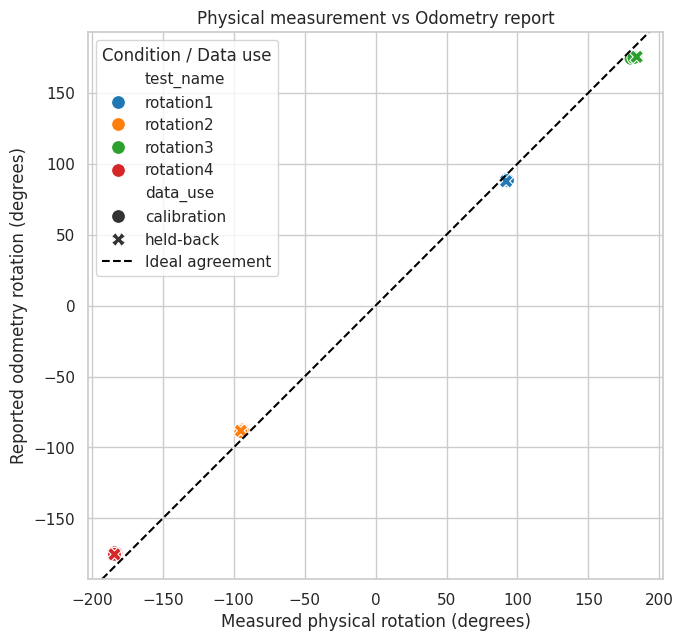

In [22]:

fig, ax = plt.subplots(figsize=(7, 7))

# Plot measured angle against odometry-reported angle
sns.scatterplot(
    data=comparison,
    x="measured_angle_deg",
    y="reported_angle_deg",
    hue="test_name",
    style="data_use",
    palette="tab10",
    s=100,
    ax=ax,
)

# Ideal agreement line
ax.axline(
    (0, 0),
    slope=1,
    color="black",
    linestyle="--",
    label="Ideal agreement"
)

ax.set(
    title="Physical measurement vs Odometry report",
    xlabel="Measured physical rotation (degrees)",
    ylabel="Reported odometry rotation (degrees)"
)

ax.set_aspect("equal", adjustable="box")
ax.legend(title="Condition / Data use")

plt.tight_layout()
plt.show()


## What to notice

- Do the two encoder counts change with opposite signs?
- Does the odometry heading change smoothly during each turn?
- Does the reported angle tend to be larger or smaller than the physical measurement?

Save the notebook with your plots. Base conclusions about physical rotation on your independent measurements, not on the commanded angle.
